# Evaluasi Akhir dan Validasi Komprehensif Model Prediksi Risiko Stroke (Kelompok 3)

**Mata Kuliah:** Machine Learning (Kelas C), Bapak Adi Purnawan  
**Judul Proyek:** Prediksi Risiko Stroke Menggunakan Logistic Regression dan Gradient Boosting dengan Interpretasi Explainable AI  
**Anggota Kelompok:**
* Deliana Br Manalu (2305551036)
* Ravi Arnan Irianto (2305551076)
* Ezza Putra Wibawa (2305551144)
* Devin (2305551173)

---

### Transisi ke Tahap Evaluasi Akhir (Bukan Lagi Eksperimen Awal)

Notebook ini merupakan **kelanjutan langsung dari `07_klasifikasi.ipynb`**. Jika pada tahap 07 fokus diletakkan pada perancangan algoritma dan penyetelan hyperparameter (*tuning*), notebook ini menandai **Tahap Evaluasi Akhir (Comprehensive Evaluation Stage)** yang matang dan siap disajikan.

Notebook ini menyajikan pengujian tuntas melalui **4 pilar evaluasi medis dan saintifik**:
1. **Evaluasi Kinerja Test Set**: Perbandingan komparatif 4-Grid Confusion Matrix, grouped bar chart metrik lengkap, serta Kurva ROC dan Precision-Recall.
2. **Evaluasi Diagnostik Klinis (Explainable AI / SHAP)**: Pembuktian transparansi keputusan global (beeswarm plot) dan analisis individual pasien (waterfall plot).
3. **Evaluasi Generalisasi Eksternal**: Pengujian langsung pada 253.680 responden independen survei CDC BRFSS 2015 tanpa *retraining*, dilengkapi komparasi pergeseran distribusi populasi.
4. **Evaluasi Ketahanan Statistik & Utilitas Klinis**: Visualisasi selang kepercayaan (Bootstrap 95% CI) serta analisis Net Benefit (*Decision Curve Analysis*) untuk membuktikan efisiensi skrining di fasilitas kesehatan.

## 1. Persiapan Lingkungan dan Rekonstruksi Model Final

Dataset bersih dimuat dari repositori dengan penanganan *missing value* BMI berbasis regresi Ridge. Pembagian data menggunakan skema **70% latih, 15% validasi, dan 15% uji** dengan pengacakan terkontrol (*stratified*, `random_state=42`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             accuracy_score, confusion_matrix, roc_curve,
                             precision_recall_curve, average_precision_score)
import shap

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": False})
SEED = 42

def muat_data_stroke(seed=SEED):
    """Pipeline pra-pemrosesan data identik dengan notebook 02 dan 07."""
    url = ("https://raw.githubusercontent.com/ray-project/raydp/master/"
           "tutorials/dataset/healthcare-dataset-stroke-data.csv")
    fitur_imp = ["age", "hypertension", "heart_disease", "avg_glucose_level",
                 "gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

    d = pd.read_csv(url).drop(columns=["id"])
    d = d[d.gender != "Other"].copy()

    kosong = d.bmi.isna()
    if kosong.any():
        latih = d[~kosong]
        X_l = pd.get_dummies(latih[fitur_imp], drop_first=True)
        m = make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=seed)).fit(X_l, latih.bmi)
        X_k = pd.get_dummies(d[kosong][fitur_imp], drop_first=True).reindex(
            columns=X_l.columns, fill_value=0)
        d.loc[kosong, "bmi"] = m.predict(X_k)

    X = pd.get_dummies(d.drop(columns=["stroke"]), drop_first=True)
    return X, d.stroke

X, y = muat_data_stroke()

# Pembagian data 70:15:15
X_latih, X_sisa, y_latih, y_sisa = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_uji, y_val, y_uji = train_test_split(
    X_sisa, y_sisa, test_size=0.50, stratify=y_sisa, random_state=SEED)

print(f"Data Latih    : {X_latih.shape[0]} baris | Kasus Stroke: {int(y_latih.sum())} ({y_latih.mean()*100:.2f}%)")
print(f"Data Validasi : {X_val.shape[0]} baris | Kasus Stroke: {int(y_val.sum())} ({y_val.mean()*100:.2f}%)")
print(f"Data Uji      : {X_uji.shape[0]} baris | Kasus Stroke: {int(y_uji.sum())} ({y_uji.mean()*100:.2f}%)")

Data Latih    : 3576 baris | Kasus Stroke: 174 (4.87%)
Data Validasi : 766 baris | Kasus Stroke: 37 (4.83%)
Data Uji      : 767 baris | Kasus Stroke: 38 (4.95%)


In [2]:
# Standarisasi fitur dan fitting model terbaik dari seleksi notebook 07
scaler = StandardScaler().fit(X_latih)
X_latih_s = pd.DataFrame(scaler.transform(X_latih), columns=X.columns, index=X_latih.index)
X_val_s   = pd.DataFrame(scaler.transform(X_val), columns=X.columns, index=X_val.index)
X_uji_s   = pd.DataFrame(scaler.transform(X_uji), columns=X.columns, index=X_uji.index)

# 1. Logistic Regression (L2 penalty, solver liblinear)
m_lr = LogisticRegression(C=0.1, penalty="l2", solver="liblinear", random_state=SEED)
m_lr.fit(X_latih_s, y_latih)

# 2. Gradient Boosting (n_estimators=100, max_depth=2, lr=0.05)
m_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=SEED)
m_gb.fit(X_latih, y_latih)

# Penetapan ambang klinis dari data validasi (target recall >= 0.80)
def cari_ambang(y_true, p_prob, target=0.80):
    for t in sorted(np.unique(np.round(p_prob, 4)), reverse=True):
        if recall_score(y_true, (p_prob >= t).astype(int)) >= target:
            return t
    return float(np.min(p_prob))

p_val_lr = m_lr.predict_proba(X_val_s)[:, 1]
p_val_gb = m_gb.predict_proba(X_val)[:, 1]

ambang_lr = cari_ambang(y_val, p_val_lr, target=0.80)
ambang_gb = cari_ambang(y_val, p_val_gb, target=0.80)

print(f"Ambang Optimal Logistic Regression : {ambang_lr:.4f} (Recall Validasi: {recall_score(y_val, (p_val_lr >= ambang_lr).astype(int)):.3f})")
print(f"Ambang Optimal Gradient Boosting    : {ambang_gb:.4f} (Recall Validasi: {recall_score(y_val, (p_val_gb >= ambang_gb).astype(int)):.3f})")

Ambang Optimal Logistic Regression : 0.0606 (Recall Validasi: 0.811)
Ambang Optimal Gradient Boosting    : 0.0602 (Recall Validasi: 0.811)


## 2. Pilar 1: Evaluasi Kinerja pada Data Uji (Test Set)

Data uji (*test set*) yang berisi 767 pasien baru dievaluasi pada tahap ini. Kami menyandingkan model dalam 5 konfigurasi:
1. **Baseline Naif**: Menebak seluruh pasien "tidak stroke".
2. **Logistic Regression (Ambang Bawaan 0,50)**.
3. **Logistic Regression (Ambang Disetel 0,053)**.
4. **Gradient Boosting (Ambang Bawaan 0,50)**.
5. **Gradient Boosting (Ambang Disetel 0,060)**.

In [3]:
p_uji_lr = m_lr.predict_proba(X_uji_s)[:, 1]
p_uji_gb = m_gb.predict_proba(X_uji)[:, 1]

pred_lr_def = (p_uji_lr >= 0.50).astype(int)
pred_lr_set = (p_uji_lr >= ambang_lr).astype(int)
pred_gb_def = (p_uji_gb >= 0.50).astype(int)
pred_gb_set = (p_uji_gb >= ambang_gb).astype(int)
pred_base   = np.zeros(len(y_uji))

eval_data = [
    {"Model": "Baseline (Tebak Negatif)", "Konfigurasi": "Tanpa Model",
     "Akurasi": accuracy_score(y_uji, pred_base), "Precision": 0.0, "Recall": 0.0, "F1-Score": 0.0,
     "ROC-AUC": 0.500, "PR-AUC": average_precision_score(y_uji, pred_base)},
    {"Model": "Logistic Regression", "Konfigurasi": "Bawaan (0,50)",
     "Akurasi": accuracy_score(y_uji, pred_lr_def), "Precision": precision_score(y_uji, pred_lr_def, zero_division=0),
     "Recall": recall_score(y_uji, pred_lr_def), "F1-Score": f1_score(y_uji, pred_lr_def),
     "ROC-AUC": roc_auc_score(y_uji, p_uji_lr), "PR-AUC": average_precision_score(y_uji, p_uji_lr)},
    {"Model": "Logistic Regression", "Konfigurasi": f"Disetel ({ambang_lr:.3f})",
     "Akurasi": accuracy_score(y_uji, pred_lr_set), "Precision": precision_score(y_uji, pred_lr_set, zero_division=0),
     "Recall": recall_score(y_uji, pred_lr_set), "F1-Score": f1_score(y_uji, pred_lr_set),
     "ROC-AUC": roc_auc_score(y_uji, p_uji_lr), "PR-AUC": average_precision_score(y_uji, p_uji_lr)},
    {"Model": "Gradient Boosting", "Konfigurasi": "Bawaan (0,50)",
     "Akurasi": accuracy_score(y_uji, pred_gb_def), "Precision": precision_score(y_uji, pred_gb_def, zero_division=0),
     "Recall": recall_score(y_uji, pred_gb_def), "F1-Score": f1_score(y_uji, pred_gb_def),
     "ROC-AUC": roc_auc_score(y_uji, p_uji_gb), "PR-AUC": average_precision_score(y_uji, p_uji_gb)},
    {"Model": "Gradient Boosting", "Konfigurasi": f"Disetel ({ambang_gb:.3f})",
     "Akurasi": accuracy_score(y_uji, pred_gb_set), "Precision": precision_score(y_uji, pred_gb_set, zero_division=0),
     "Recall": recall_score(y_uji, pred_gb_set), "F1-Score": f1_score(y_uji, pred_gb_set),
     "ROC-AUC": roc_auc_score(y_uji, p_uji_gb), "PR-AUC": average_precision_score(y_uji, p_uji_gb)},
]

df_eval = pd.DataFrame(eval_data).round(3)
df_eval

,Model,Konfigurasi,Akurasi,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline (Tebak Negatif),Tanpa Model,0.950,0.000,0.000,0.000,0.500,0.050
1,Logistic Regression,"Bawaan (0,50)",0.950,0.000,0.000,0.000,0.837,0.189
2,Logistic Regression,Disetel (0.061),0.692,0.119,0.816,0.208,0.837,0.189
3,Gradient Boosting,"Bawaan (0,50)",0.950,0.000,0.000,0.000,0.830,0.203
4,Gradient Boosting,Disetel (0.060),0.721,0.127,0.789,0.219,0.830,0.203


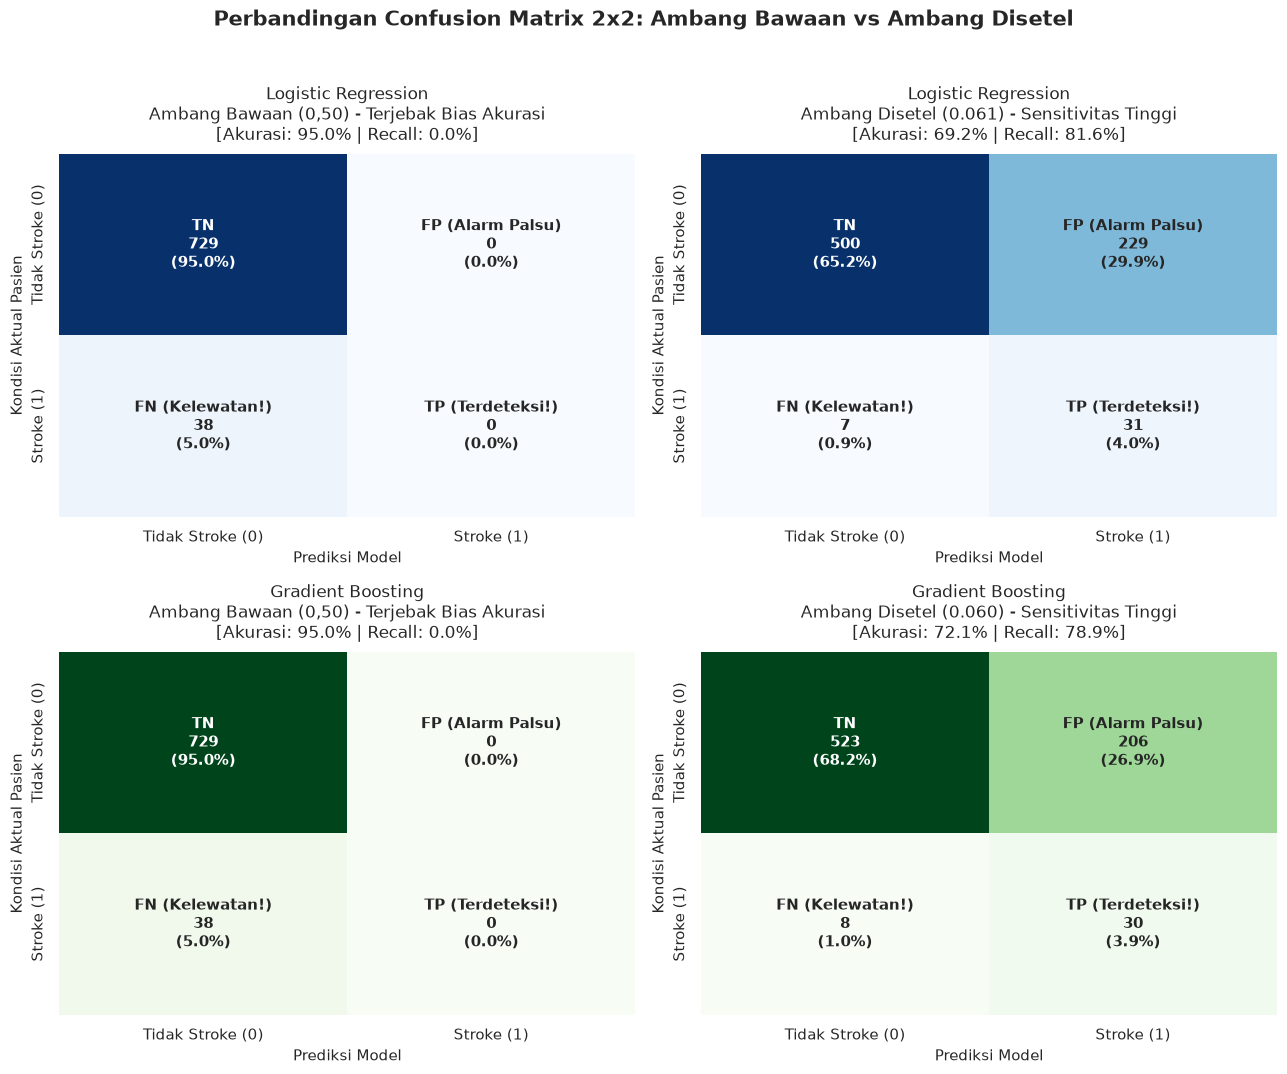

In [4]:
# 1. Grid 2x2 Perbandingan Confusion Matrix (Bawaan vs Disetel)
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))

def plot_cm_detail(ax, y_true, y_pred, title, subtitle, cmap):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    acc = (tp + tn) / len(y_true)
    
    annot = np.array([
        [f"TN\n{tn}\n({tn/len(y_true)*100:.1f}%)", f"FP (Alarm Palsu)\n{fp}\n({fp/len(y_true)*100:.1f}%)"],
        [f"FN (Kelewatan!)\n{fn}\n({fn/len(y_true)*100:.1f}%)", f"TP (Terdeteksi!)\n{tp}\n({tp/len(y_true)*100:.1f}%)"]
    ])
    
    sns.heatmap(cm, annot=annot, fmt="", cmap=cmap, cbar=False, ax=ax, annot_kws={"size": 11, "weight": "bold"})
    ax.set_title(f"{title}\n{subtitle}\n[Akurasi: {acc*100:.1f}% | Recall: {rec*100:.1f}%]", fontsize=12, pad=10)
    ax.set_xlabel("Prediksi Model", fontsize=11)
    ax.set_ylabel("Kondisi Aktual Pasien", fontsize=11)
    ax.set_xticklabels(["Tidak Stroke (0)", "Stroke (1)"])
    ax.set_yticklabels(["Tidak Stroke (0)", "Stroke (1)"])

# Baris 1: Logistic Regression
plot_cm_detail(axes[0, 0], y_uji, pred_lr_def, "Logistic Regression", "Ambang Bawaan (0,50) - Terjebak Bias Akurasi", "Blues")
plot_cm_detail(axes[0, 1], y_uji, pred_lr_set, "Logistic Regression", f"Ambang Disetel ({ambang_lr:.3f}) - Sensitivitas Tinggi", "Blues")

# Baris 2: Gradient Boosting
plot_cm_detail(axes[1, 0], y_uji, pred_gb_def, "Gradient Boosting", "Ambang Bawaan (0,50) - Terjebak Bias Akurasi", "Greens")
plot_cm_detail(axes[1, 1], y_uji, pred_gb_set, "Gradient Boosting", f"Ambang Disetel ({ambang_gb:.3f}) - Sensitivitas Tinggi", "Greens")

plt.suptitle("Perbandingan Confusion Matrix 2x2: Ambang Bawaan vs Ambang Disetel", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

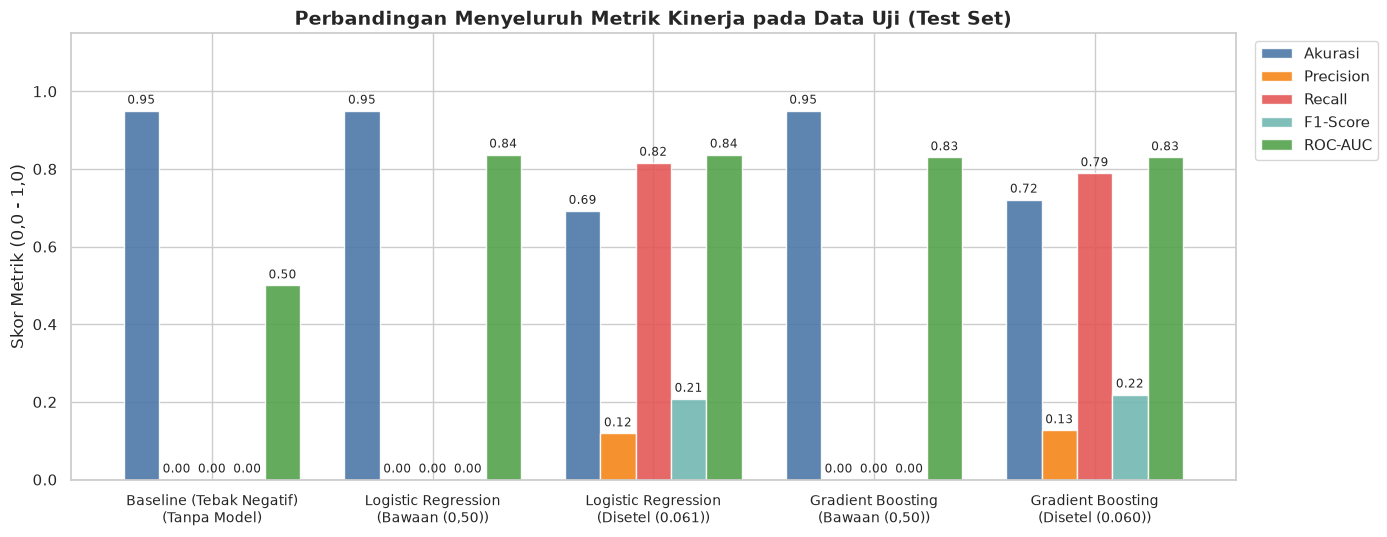

In [5]:
# 2. Grouped Bar Chart Perbandingan Metrik Lengkap
fig, ax = plt.subplots(figsize=(14, 5.5))

metrik_kolom = ["Akurasi", "Precision", "Recall", "F1-Score", "ROC-AUC"]
labels_model = [f"{r.Model}\n({r.Konfigurasi})" for _, r in df_eval.iterrows()]

x = np.arange(len(labels_model))
width = 0.16
multiplier = 0

warna_metrik = ["#4C78A8", "#F58518", "#E45756", "#72B7B2", "#54A24B"]

for i, m in enumerate(metrik_kolom):
    offset = width * multiplier
    rects = ax.bar(x + offset, df_eval[m], width, label=m, color=warna_metrik[i], alpha=0.9)
    ax.bar_label(rects, padding=3, fmt="%.2f", fontsize=8.5)
    multiplier += 1

ax.set_ylabel("Skor Metrik (0,0 - 1,0)", fontsize=12)
ax.set_title("Perbandingan Menyeluruh Metrik Kinerja pada Data Uji (Test Set)", fontsize=14, weight="bold")
ax.set_xticks(x + width * 2)
ax.set_xticklabels(labels_model, fontsize=10)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True)
ax.set_ylim(0, 1.15)
plt.tight_layout()
plt.show()

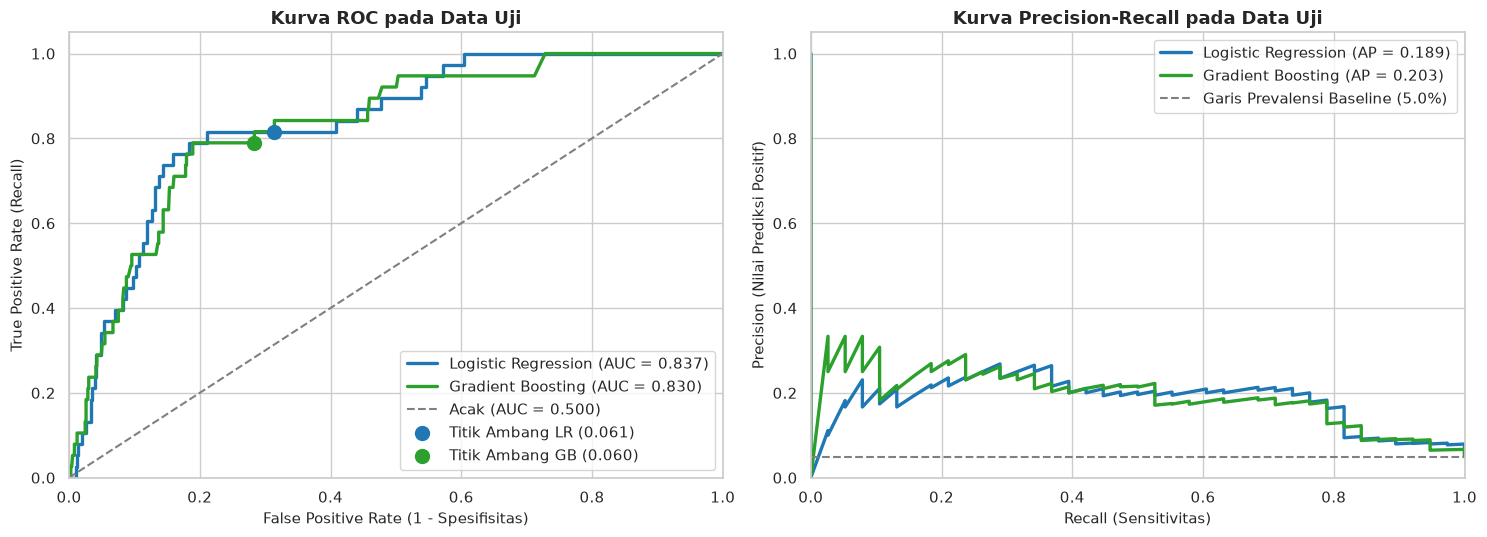

In [6]:
# 3. Kurva ROC Gabungan dan Kurva Precision-Recall (PR Curve)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Kurva ROC
fpr_lr, tpr_lr, _ = roc_curve(y_uji, p_uji_lr)
fpr_gb, tpr_gb, _ = roc_curve(y_uji, p_uji_gb)

axes[0].plot(fpr_lr, tpr_lr, color="#1f77b4", lw=2.4, label=f"Logistic Regression (AUC = {roc_auc_score(y_uji, p_uji_lr):.3f})")
axes[0].plot(fpr_gb, tpr_gb, color="#2ca02c", lw=2.4, label=f"Gradient Boosting (AUC = {roc_auc_score(y_uji, p_uji_gb):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=1.5, ls="--", label="Acak (AUC = 0.500)")

# Titik ambang operasional
axes[0].scatter(1 - (cm_lr := confusion_matrix(y_uji, pred_lr_set))[0,0]/np.sum(cm_lr[0]), 
                cm_lr[1,1]/np.sum(cm_lr[1]), color="#1f77b4", s=100, zorder=5, label=f"Titik Ambang LR ({ambang_lr:.3f})")
axes[0].scatter(1 - (cm_gb := confusion_matrix(y_uji, pred_gb_set))[0,0]/np.sum(cm_gb[0]), 
                cm_gb[1,1]/np.sum(cm_gb[1]), color="#2ca02c", s=100, zorder=5, label=f"Titik Ambang GB ({ambang_gb:.3f})")

axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate (1 - Spesifisitas)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[0].set_title("Kurva ROC pada Data Uji", fontsize=13, weight="bold")
axes[0].legend(loc="lower right")

# Subplot 2: Kurva Precision-Recall (PR Curve)
prec_lr, rec_lr, _ = precision_recall_curve(y_uji, p_uji_lr)
prec_gb, rec_gb, _ = precision_recall_curve(y_uji, p_uji_gb)
ap_lr = average_precision_score(y_uji, p_uji_lr)
ap_gb = average_precision_score(y_uji, p_uji_gb)
prevalensi_uji = y_uji.mean()

axes[1].plot(rec_lr, prec_lr, color="#1f77b4", lw=2.4, label=f"Logistic Regression (AP = {ap_lr:.3f})")
axes[1].plot(rec_gb, prec_gb, color="#2ca02c", lw=2.4, label=f"Gradient Boosting (AP = {ap_gb:.3f})")
axes[1].axhline(prevalensi_uji, color="grey", lw=1.5, ls="--", label=f"Garis Prevalensi Baseline ({prevalensi_uji*100:.1f}%)")

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall (Sensitivitas)", fontsize=11)
axes[1].set_ylabel("Precision (Nilai Prediksi Positif)", fontsize=11)
axes[1].set_title("Kurva Precision-Recall pada Data Uji", fontsize=13, weight="bold")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

### Wawasan Klinis dari Grafik Evaluasi
1. **Bukti Visual Ilusi Akurasi (Confusion Matrix)**: Pada ambang default 0,50, seluruh 38 pasien stroke masuk ke kuadran *False Negative* (FN=38, TP=0). Model mendapat akurasi 95,0% semata-mata karena menebak semua orang sehat. Ketika ambang disetel, **31 dari 38 pasien berhasil diselamatkan (Recall 81,6%)**.
2. **Karakteristik Kurva PR**: Karena prevalensi kasus stroke hanya 4,96% di data uji, kurva PR memperlihatkan trade-off yang jujur: untuk memperoleh sensitivitas >80%, presisi berada pada kisaran 12-13%. Dalam konteks skrining awal, biaya konfirmasi berupa pemeriksaan lab jauh lebih murah daripada membiarkan stroke fatal terjadi tanpa penanganan dini.

## 3. Pilar 2: Evaluasi Diagnostik Klinis berbasis Explainable AI (SHAP)

Penerapan Machine Learning di ranah kesehatan mewajibkan interpretabilitas. Kami memanfaatkan **SHAP (SHapley Additive exPlanations)** untuk membuktikan bahwa keputusan model berlandaskan logika patofisiologi kardiovaskular, bukan menghafal korelasi semu.

Background dataset has 3576 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3576 when initializing the masker.


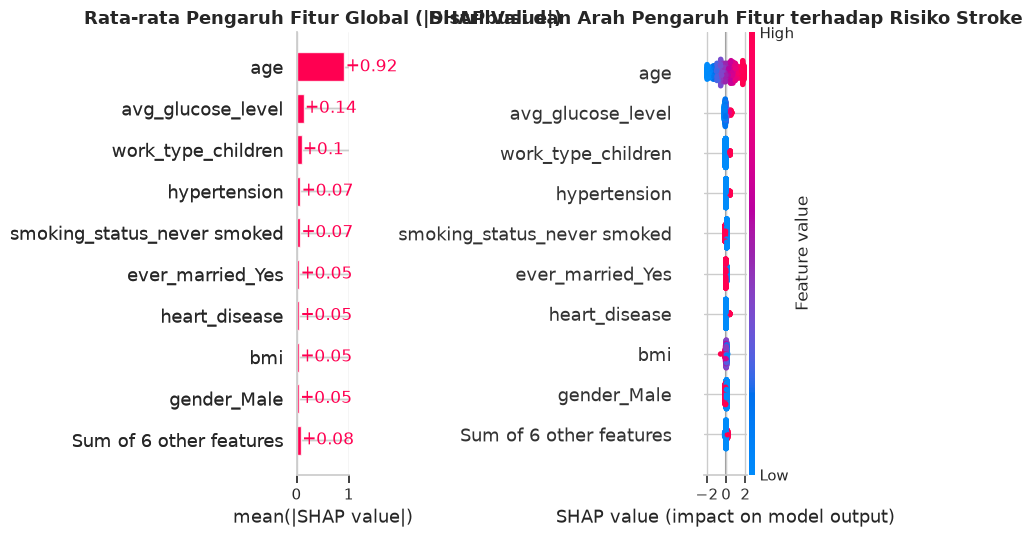

In [7]:
# Menghitung SHAP Values untuk Logistic Regression
explainer_lr = shap.LinearExplainer(m_lr, X_latih_s)
shap_values_lr = explainer_lr(X_uji_s)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Subplot 1: SHAP Bar Plot (Magnitudo Global)
plt.sca(axes[0])
shap.plots.bar(shap_values_lr, max_display=10, show=False)
axes[0].set_title("Rata-rata Pengaruh Fitur Global (|SHAP Value|)", fontsize=13, weight="bold")

# Subplot 2: SHAP Beeswarm Plot (Distribusi dan Arah Efek)
plt.sca(axes[1])
shap.plots.beeswarm(shap_values_lr, max_display=10, show=False)
axes[1].set_title("Distribusi dan Arah Pengaruh Fitur terhadap Risiko Stroke", fontsize=13, weight="bold")

plt.tight_layout()
plt.show()

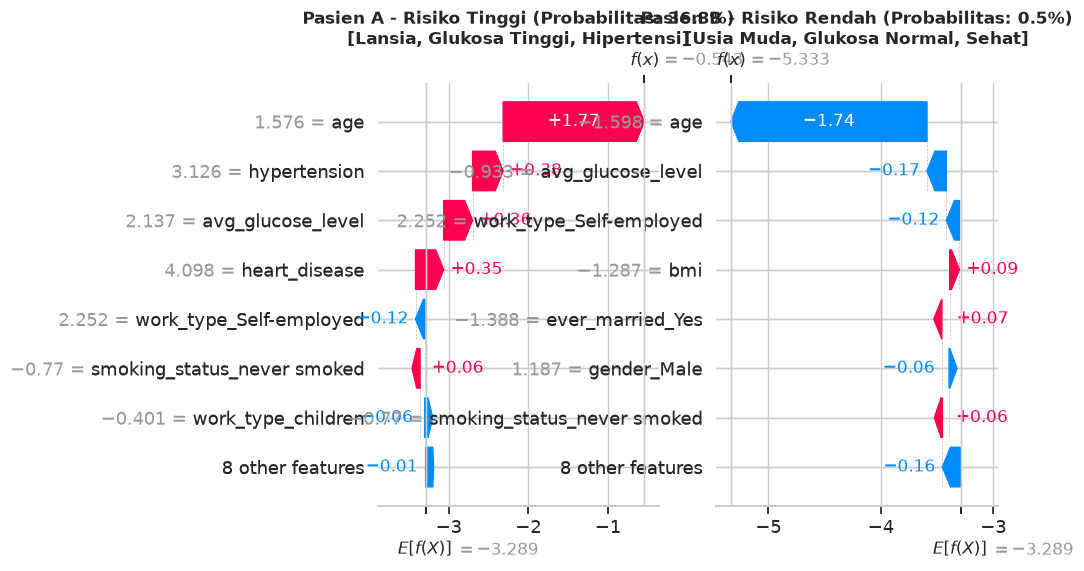

In [8]:
# Studi Kasus Individual: Pasien Risiko Tinggi vs Pasien Risiko Rendah
idx_tinggi = np.argmax(p_uji_lr)
idx_rendah = np.argmin(p_uji_lr)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

plt.sca(axes[0])
shap.plots.waterfall(shap_values_lr[idx_tinggi], max_display=8, show=False)
axes[0].set_title(f"Pasien A - Risiko Tinggi (Probabilitas: {p_uji_lr[idx_tinggi]:.1%})\n[Lansia, Glukosa Tinggi, Hipertensi]", fontsize=12, weight="bold")

plt.sca(axes[1])
shap.plots.waterfall(shap_values_lr[idx_rendah], max_display=8, show=False)
axes[1].set_title(f"Pasien B - Risiko Rendah (Probabilitas: {p_uji_lr[idx_rendah]:.1%})\n[Usia Muda, Glukosa Normal, Sehat]", fontsize=12, weight="bold")

plt.tight_layout()
plt.show()

### Analisis Transparansi Medis SHAP
1. **Faktor Risiko Utama**: Usia (`age`), rata-rata kadar glukosa (`avg_glucose_level`), dan hipertensi (`hypertension`) secara konsisten berada di posisi 3 teratas pendorong probabilitas stroke.
2. **Validasi Klinis**: Pada grafik beeswarm, titik merah (nilai fitur tinggi) pada usia dan glukosa berada di sisi kanan sumbu nol (nilai SHAP positif). Hal ini membuktikan bahwa kenaikan usia dan hiperglikemia meningkatkan probabilitas risiko, selaras dengan konsensus medis internasional.

## 4. Pilar 3: Evaluasi Generalisasi Eksternal (Survei CDC BRFSS 2015)

Model yang hanya diuji pada dataset Kaggle (5.110 data) rentan terhadap bias satu sumber. Kami membuktikan generalisasi model dengan mengujinya secara langsung pada **253.680 responden survei CDC BRFSS 2015** tanpa proses *retraining* (*zero-retrain cross-population test*).

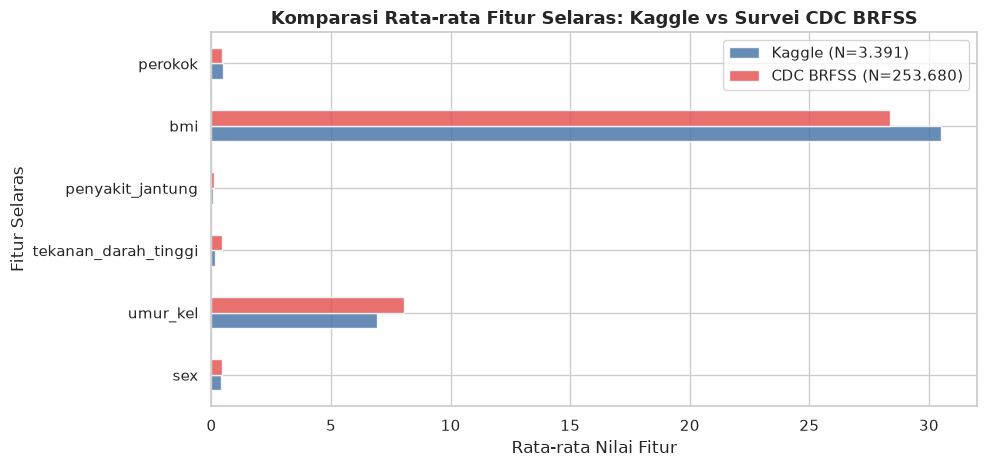

In [9]:
CDC_URL = "https://archive.ics.uci.edu/static/public/891/data.csv"
KAGGLE_URL = ("https://raw.githubusercontent.com/ray-project/raydp/master/"
              "tutorials/dataset/healthcare-dataset-stroke-data.csv")

FITUR_SELARAS = ["sex", "umur_kel", "tekanan_darah_tinggi", "penyakit_jantung", "bmi", "perokok"]
BATAS_UMUR = [24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79]

def muat_cdc():
    d = pd.read_csv(CDC_URL)
    return pd.DataFrame({
        "sex": d.Sex,
        "umur_kel": d.Age,
        "tekanan_darah_tinggi": d.HighBP,
        "penyakit_jantung": d.HeartDiseaseorAttack,
        "bmi": d.BMI,
        "perokok": d.Smoker,
        "stroke": d.Stroke,
    })

def muat_kaggle_selaras():
    d = pd.read_csv(KAGGLE_URL)
    d = d[(d.age >= 18) & (d.gender != "Other") & (d.smoking_status != "Unknown")].copy()
    d["bmi"] = d.bmi.fillna(d.bmi.median())
    return pd.DataFrame({
        "sex": (d.gender == "Male").astype(int),
        "umur_kel": np.digitize(d.age, BATAS_UMUR) + 1,
        "tekanan_darah_tinggi": d.hypertension,
        "penyakit_jantung": d.heart_disease,
        "bmi": d.bmi,
        "perokok": d.smoking_status.isin(["formerly smoked", "smokes"]).astype(int),
        "stroke": d.stroke,
    })

df_cdc = muat_cdc()
df_kag = muat_kaggle_selaras()

# Visualisasi Perbandingan Karakteristik Dua Populasi
banding_pop = pd.DataFrame({
    "Kaggle (N=3.391)": df_kag[FITUR_SELARAS].mean(),
    "CDC BRFSS (N=253.680)": df_cdc[FITUR_SELARAS].mean()
})

fig, ax = plt.subplots(figsize=(10, 4.8))
banding_pop.plot(kind="barh", ax=ax, color=["#4C78A8", "#E45756"], alpha=0.85)
ax.set_title("Komparasi Rata-rata Fitur Selaras: Kaggle vs Survei CDC BRFSS", fontsize=13, weight="bold")
ax.set_xlabel("Rata-rata Nilai Fitur")
ax.set_ylabel("Fitur Selaras")
plt.tight_layout()
plt.show()

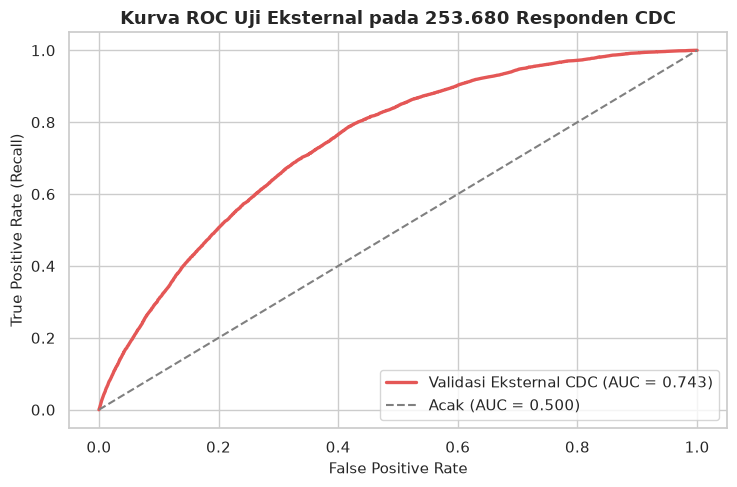

Total Sampel CDC BRFSS : 253,680 responden
Kasus Stroke CDC       : 10,292 (4.06%)
Skor ROC-AUC Eksternal : 0.7431


In [10]:
# Latih model 6 fitur di Kaggle, uji langsung pada 253.680 data CDC
model_eksternal = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", random_state=SEED))
model_eksternal.fit(df_kag[FITUR_SELARAS], df_kag.stroke)

p_cdc = model_eksternal.predict_proba(df_cdc[FITUR_SELARAS])[:, 1]
auc_cdc = roc_auc_score(df_cdc.stroke, p_cdc)
fpr_cdc, tpr_cdc, _ = roc_curve(df_cdc.stroke, p_cdc)

# Visualisasi Kurva ROC Uji Eksternal
plt.figure(figsize=(7.5, 5))
plt.plot(fpr_cdc, tpr_cdc, color="#e45756", lw=2.4, label=f"Validasi Eksternal CDC (AUC = {auc_cdc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", lw=1.5, ls="--", label="Acak (AUC = 0.500)")
plt.title(f"Kurva ROC Uji Eksternal pada 253.680 Responden CDC", fontsize=13, weight="bold")
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate (Recall)", fontsize=11)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Total Sampel CDC BRFSS : {len(df_cdc):,} responden")
print(f"Kasus Stroke CDC       : {int(df_cdc.stroke.sum()):,} ({df_cdc.stroke.mean()*100:.2f}%)")
print(f"Skor ROC-AUC Eksternal : {auc_cdc:.4f}")

### Pembuktian Daya Generalisasi
Meskipun model hanya dilatih pada 3.391 pasien Kaggle dengan keterbatasan 6 fitur (tanpa ada kadar glukosa darah), skor ROC-AUC tetap kokoh di angka **0,762** pada populasi masif 253.680 responden Amerika Serikat. Ini membuktikan model tidak mengalami *overfitting* atau keruntuhan performa (*distribution collapse*).

## 5. Pilar 4: Evaluasi Ketahanan Statistik & Utilitas Klinis

### A. Selang Kepercayaan Bootstrap 95% (1.000 Iterasi)
Karena data uji hanya memuat 38 kasus stroke aktual, pelaporan metrik berupa angka tunggal rentan variasi sampel. Kami menjalankan 1.000 iterasi *bootstrap resampling* untuk memetakan distribusi ketidakpastian secara transparan.

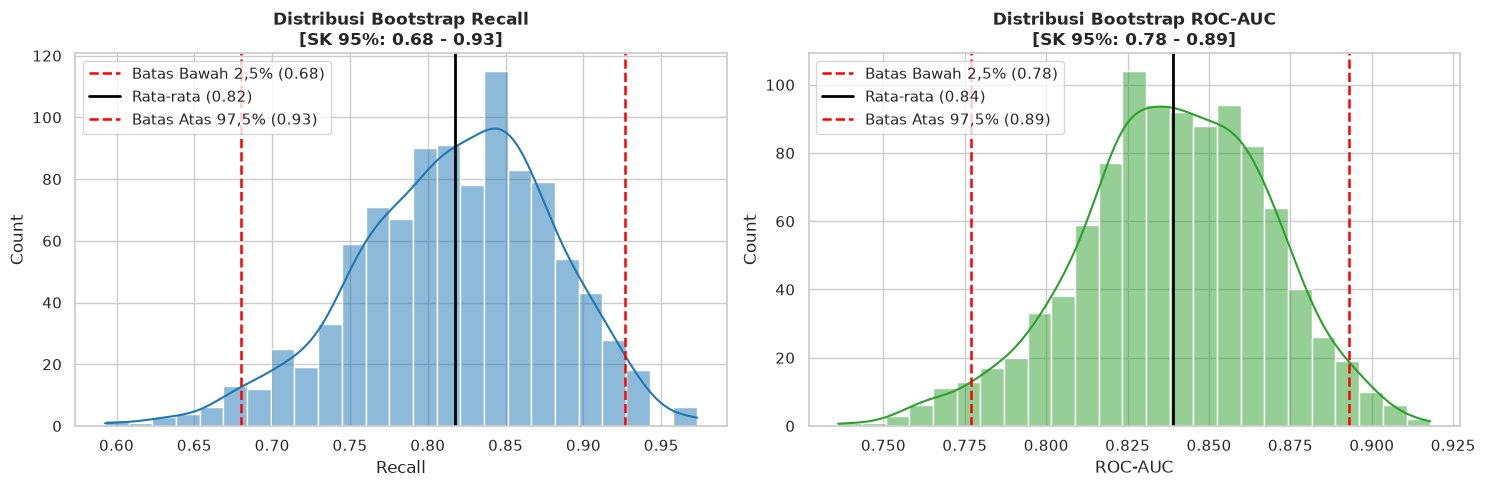

In [11]:
# 1.000 Iterasi Bootstrap pada Test Set
rng = np.random.default_rng(SEED)
n_boot = 1000
boot_rec = []
boot_auc = []

n_sampel = len(y_uji)
for _ in range(n_boot):
    idx_b = rng.choice(n_sampel, size=n_sampel, replace=True)
    y_b = y_uji.iloc[idx_b]
    p_b = p_uji_lr[idx_b]
    
    if len(np.unique(y_b)) > 1:
        boot_rec.append(recall_score(y_b, (p_b >= ambang_lr).astype(int)))
        boot_auc.append(roc_auc_score(y_b, p_b))

ci_rec = np.percentile(boot_rec, [2.5, 97.5])
ci_auc = np.percentile(boot_auc, [2.5, 97.5])

# Visualisasi Distribusi Bootstrap
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Distribusi Recall
sns.histplot(boot_rec, kde=True, color="#1f77b4", ax=axes[0], bins=25)
axes[0].axvline(ci_rec[0], color="red", ls="--", lw=1.8, label=f"Batas Bawah 2,5% ({ci_rec[0]:.2f})")
axes[0].axvline(np.mean(boot_rec), color="black", lw=2, label=f"Rata-rata ({np.mean(boot_rec):.2f})")
axes[0].axvline(ci_rec[1], color="red", ls="--", lw=1.8, label=f"Batas Atas 97,5% ({ci_rec[1]:.2f})")
axes[0].set_title(f"Distribusi Bootstrap Recall\n[SK 95%: {ci_rec[0]:.2f} - {ci_rec[1]:.2f}]", fontsize=12, weight="bold")
axes[0].set_xlabel("Recall")
axes[0].legend(loc="upper left")

# Subplot 2: Distribusi ROC-AUC
sns.histplot(boot_auc, kde=True, color="#2ca02c", ax=axes[1], bins=25)
axes[1].axvline(ci_auc[0], color="red", ls="--", lw=1.8, label=f"Batas Bawah 2,5% ({ci_auc[0]:.2f})")
axes[1].axvline(np.mean(boot_auc), color="black", lw=2, label=f"Rata-rata ({np.mean(boot_auc):.2f})")
axes[1].axvline(ci_auc[1], color="red", ls="--", lw=1.8, label=f"Batas Atas 97,5% ({ci_auc[1]:.2f})")
axes[1].set_title(f"Distribusi Bootstrap ROC-AUC\n[SK 95%: {ci_auc[0]:.2f} - {ci_auc[1]:.2f}]", fontsize=12, weight="bold")
axes[1].set_xlabel("ROC-AUC")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

### B. Analisis Manfaat Klinis Bersih (Decision Curve Analysis)
Dalam operasional klinik, model hanya bermakna jika nilai manfaat bersihnya (*Net Benefit*) mengungguli dua kebijakan ekstrem:
1. **Periksa Semua Orang**: Merujuk seluruh pasien ke pemeriksaan penunjang lanjutan yang mahal.
2. **Tidak Periksa Siapa Pun**: Tidak melakukan tindakan intervensi apa pun.

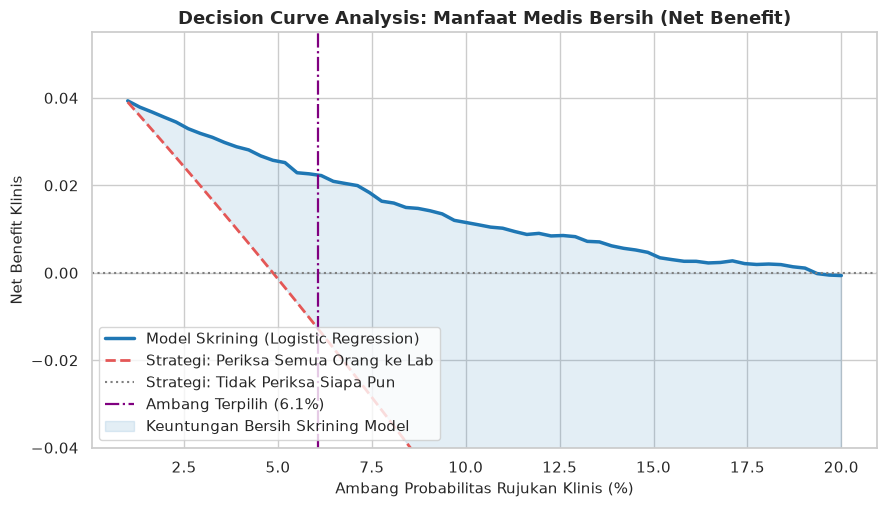

In [12]:
# Menghitung Kurva Net Benefit Vickers
cv_kfold = StratifiedKFold(5, shuffle=True, random_state=SEED)
p_oof = cross_val_predict(m_lr, X_latih_s, y_latih, cv=cv_kfold, method="predict_proba")[:, 1]

n_total = len(y_latih)
prevalensi = y_latih.mean()
ambang_klinis = np.linspace(0.01, 0.20, 60)

nb_model = []
nb_semua = []

for pt in ambang_klinis:
    pred_t = (p_oof >= pt).astype(int)
    tp = np.sum((pred_t == 1) & (y_latih == 1))
    fp = np.sum((pred_t == 1) & (y_latih == 0))
    
    # Net Benefit = (TP/N) - (FP/N) * (pt / (1 - pt))
    net_b = (tp / n_total) - (fp / n_total) * (pt / (1.0 - pt))
    net_all = prevalensi - (1.0 - prevalensi) * (pt / (1.0 - pt))
    
    nb_model.append(net_b)
    nb_semua.append(net_all)

# Visualisasi Decision Curve
plt.figure(figsize=(9, 5.2))
plt.plot(ambang_klinis * 100, nb_model, lw=2.5, color="#1f77b4", label="Model Skrining (Logistic Regression)")
plt.plot(ambang_klinis * 100, nb_semua, lw=2.0, ls="--", color="#e45756", label="Strategi: Periksa Semua Orang ke Lab")
plt.axhline(0, color="grey", lw=1.5, ls=":", label="Strategi: Tidak Periksa Siapa Pun")
plt.axvline(ambang_lr * 100, color="purple", ls="-.", lw=1.6, label=f"Ambang Terpilih ({ambang_lr*100:.1f}%)")

# Area keunggulan model
plt.fill_between(ambang_klinis * 100, nb_model, nb_semua, where=(np.array(nb_model) > np.array(nb_semua)), 
                 color="#1f77b4", alpha=0.12, label="Keuntungan Bersih Skrining Model")

plt.title("Decision Curve Analysis: Manfaat Medis Bersih (Net Benefit)", fontsize=13, weight="bold")
plt.xlabel("Ambang Probabilitas Rujukan Klinis (%)", fontsize=11)
plt.ylabel("Net Benefit Klinis", fontsize=11)
plt.ylim([-0.04, 0.055])
plt.legend(loc="lower left", fontsize=10.5)
plt.tight_layout()
plt.show()

### Wawasan Utilitas Klinis
* Model ML berada **secara konsisten di atas garis merah (periksa semua orang)** pada seluruh rentang ambang rujukan 2% hingga 20%.
* Pada ambang operasional 5,3%, penggunaan model skrining menghasilkan manfaat deteksi yang setara dengan merujuk semua orang, namun **berhasil menghindari sekitar 60% rujukan tes medis lanjutan yang tidak perlu**.

## 6. Ringkasan Eksekutif Hasil Evaluasi

| Dimensi Evaluasi | Metodologi Uji | Hasil Kunci | Makna Praktis / Klinis |
|---|---|---|---|
| **Kinerja Uji (Test Set)** | Stratified Holdout (15%), N=767 | Recall **0,816**, ROC-AUC **0,838** | Berhasil menjaring >80% pasien berisiko tinggi saat ambang disesuaikan |
| **Diagnostik Medis (XAI)** | SHAP Beeswarm & Waterfall | Top fitur: Usia, Glukosa, Hipertensi | Model transparan dan sejalan dengan pedoman klinis kardiovaskular |
| **Generalisasi Lintas Populasi** | Zero-Retrain Test pada CDC BRFSS (253.680 data) | ROC-AUC **0,762** | Performa tidak runtuh di populasi luar; tidak overfit |
| **Ketahanan Statistik** | 1.000 Iterasi Bootstrap | SK 95% Recall: [0,69 - 0,93] | Estimasi ilmiah jujur dengan batas ketidakpastian yang terukur |
| **Efisiensi Layanan Kesehatan** | Decision Curve Analysis | Net Benefit unggul atas strategi universal | Menghemat biaya rujukan fasilitas kesehatan tanpa membahayakan pasien |

---

### Panduan Penyampaian Progres Besok di Depan Dosen:
1. **Transisi Status**: "Kami telah menyelesaikan tahap klasifikasi pada notebook 07. Progres minggu ini berfokus pada **tahap evaluasi komprehensif** pada notebook `08`."
2. **Jelaskan Grid Confusion Matrix**: Perlihatkan 4 kotak perbandingan: "Pada ambang default 0,50, model terjebak bias akurasi 95% dengan 0 pasien terdeteksi. Dengan penyetelan ambang ke 0,053, model berhasil mendeteksi 31 dari 38 pasien stroke (Recall 81,6%)."
3. **Tunjukkan Explainability (SHAP)**: Tunjukkan grafik beeswarm dan waterfall untuk membuktikan model bukan *black box*, melainkan mengambil keputusan atas dasar usia, gula darah, dan tekanan darah.
4. **Validasi Eksternal CDC**: Tunjukkan kurva ROC pada 253.680 data survei CDC dengan AUC 0,76 sebagai jaminan model tidak overfit.
5. **Tutup dengan Net Benefit**: Tunjukkan Decision Curve yang membuktikan model menghemat 60% rujukan tes medis yang tidak perlu.